# 1. Stationary Target

The target of the earlier connection_slots notebooks, without the output reversals, learned by the algorithm of step 2
of the meta progression (`../algorithm/2_pruning_and_depth.ipynb`).

**Problem.** `problems.SignLTUTarget`: `n_inputs` standard normal inputs, and `n_target_ltus` target LTUs that each read
`fan_in` inputs with weights of ±1 and a zero threshold. Each target LTU outputs ±1. One output sums the target LTUs
through weights of ±1, with no scaling. The output noise has std 0.1. The target never changes.

**Algorithm.** `algorithms.CountAllConnections` (in this folder): `PruneAndMove` with 1 depth, whose budget counts
every connection except the biases, the output's connections included. The output reads x and every LTU, so a new LTU
takes `INITIAL_LTU_CONNECTIONS` + 1 connections. At step 0, as many LTUs as the budget holds.

5 seeds, 100k steps.

In [1]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
import jax
jax.config.update('jax_platforms', 'cuda')

from phd.sandbox.unit_search.algorithm import experiment, problems
from phd.sandbox.unit_search.connection_slots import algorithms

assert jax.default_backend() == 'gpu'
%matplotlib inline

In [2]:
N_INPUTS = 108
N_TARGET_LTUS = 4
INPUTS_PER_TARGET_LTU = 4

MAX_LTUS = 256
INITIAL_LTU_CONNECTIONS = 20
MAX_CONNECTIONS = 2048
# The output reads every input and every LTU, and its connections count too.
INITIAL_LTU_COUNT = min((MAX_CONNECTIONS - N_INPUTS) // (INITIAL_LTU_CONNECTIONS + 1), MAX_LTUS)

LEARNING_STEPS = 100_000

prune and move, all connections in the budget: RMSE over the last 10% 0.209 ; at the end, 125 LTUs and 2038 connections in the budget (16s)


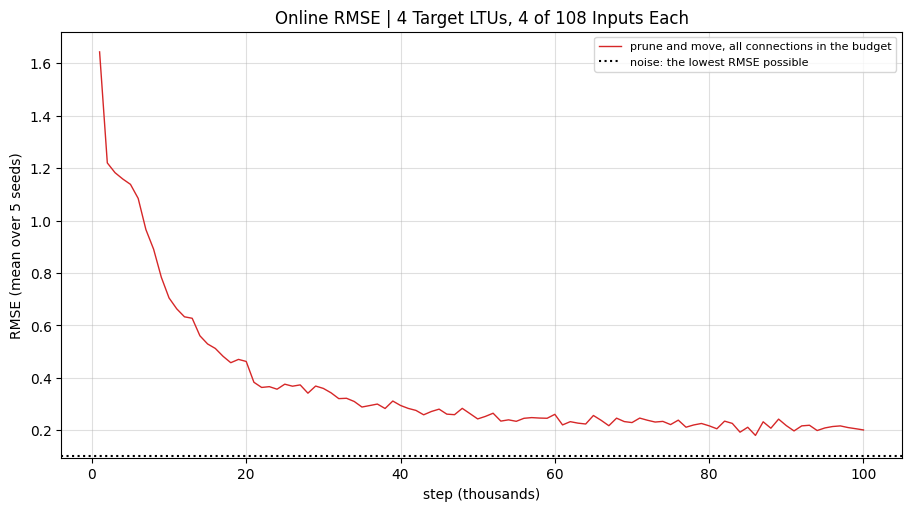

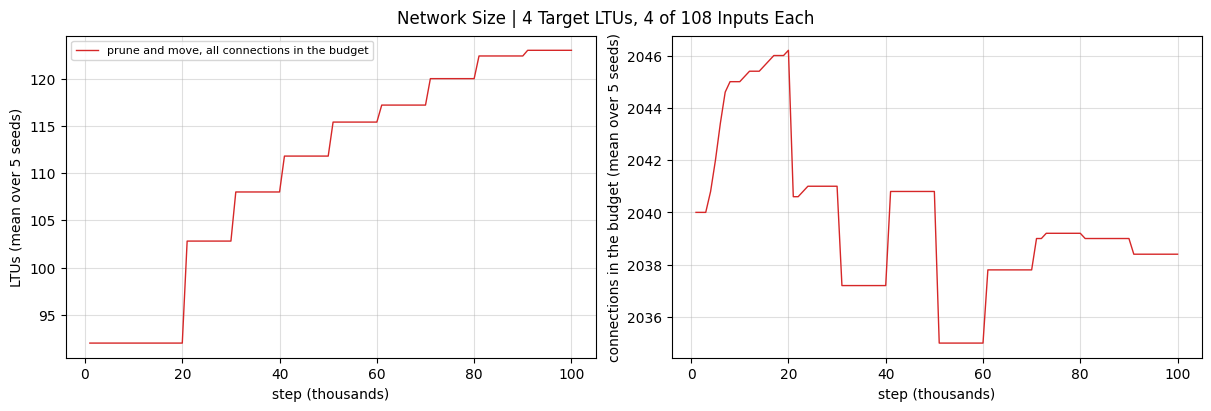

In [3]:
problem = problems.SignLTUTarget(
    n_inputs = N_INPUTS,
    n_target_ltus = N_TARGET_LTUS,
    fan_in = INPUTS_PER_TARGET_LTU,
)
methods = {'prune and move, all connections in the budget': algorithms.CountAllConnections(
    n_inputs = problem.n_inputs,
    n_outputs = problem.n_outputs,
    width = INITIAL_LTU_COUNT,
    max_ltus = MAX_LTUS,
    budget = MAX_CONNECTIONS,
    initial_fan_in = INITIAL_LTU_CONNECTIONS,
)}
rmse, records = experiment.run(methods, problem, steps=LEARNING_STEPS)
title = f'{N_TARGET_LTUS} Target LTUs, {INPUTS_PER_TARGET_LTU} of {N_INPUTS} Inputs Each'
experiment.plot(rmse, problem, f'Online RMSE | {title}')
experiment.plot_sizes(records, f'Network Size | {title}')